In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

In [2]:
from sklearn.datasets import load_diabetes

data = load_diabetes()

df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target

df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
X = df.drop("target", axis=1)
y = df["target"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [5]:
# Decision Tree Regressor
dt = DecisionTreeRegressor(
    max_depth=4,
    random_state=42
)

# Train
dt.fit(X_train, y_train)

# Prediction
dt_pred_train = dt.predict(X_train)
dt_pred_test = dt.predict(X_test)

# Evaluation
print("Decision Tree Regressor")

print("Training R2 Score:",
      r2_score(y_train, dt_pred_train))

print("Testing R2 Score:",
      r2_score(y_test, dt_pred_test))

print("MAE:",
      mean_absolute_error(y_test, dt_pred_test))

print("MSE:",
      mean_squared_error(y_test, dt_pred_test))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, dt_pred_test)))

Decision Tree Regressor
Training R2 Score: 0.5845804478210278
Testing R2 Score: 0.3263754171777956
MAE: 47.04539158640984
MSE: 3568.9652613232283
RMSE: 59.74081738077601


In [6]:
# Random Forest Regressor
rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=4,
    random_state=42
)

# Train
rf.fit(X_train, y_train)

# Prediction
rf_pred_train = rf.predict(X_train)
rf_pred_test = rf.predict(X_test)

# Evaluation
print("Random Forest Regressor")

print("Training R2 Score:",
      r2_score(y_train, rf_pred_train))

print("Testing R2 Score:",
      r2_score(y_test, rf_pred_test))

print("MAE:",
      mean_absolute_error(y_test, rf_pred_test))

print("MSE:",
      mean_squared_error(y_test, rf_pred_test))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, rf_pred_test)))

Random Forest Regressor
Training R2 Score: 0.6624809258640015
Testing R2 Score: 0.46457733976829396
MAE: 43.50335789484029
MSE: 2836.7505035020235
RMSE: 53.26115379431827


# Compare Both Models

In [7]:
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],

    "Train Accuracy (R2)": [
        r2_score(y_train, dt_pred_train),
        r2_score(y_train, rf_pred_train)
    ],

    "Test Accuracy (R2)": [
        r2_score(y_test, dt_pred_test),
        r2_score(y_test, rf_pred_test)
    ],

    "MAE": [
        mean_absolute_error(y_test, dt_pred_test),
        mean_absolute_error(y_test, rf_pred_test)
    ],

    "RMSE": [
        np.sqrt(mean_squared_error(y_test, dt_pred_test)),
        np.sqrt(mean_squared_error(y_test, rf_pred_test))
    ]
})

comparison

,Model,Train Accuracy (R2),Test Accuracy (R2),MAE,RMSE
0,Decision Tree,0.584580,0.326375,47.045392,59.740817
1,Random Forest,0.662481,0.464577,43.503358,53.261154


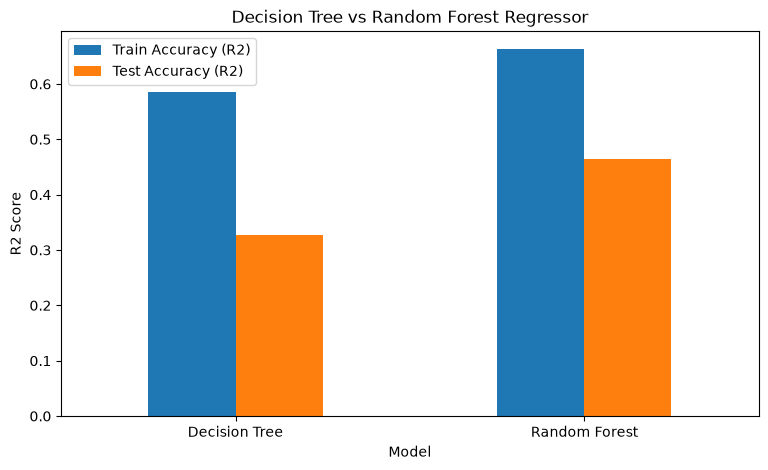

In [8]:
comparison.plot(
    x="Model",
    y=["Train Accuracy (R2)", "Test Accuracy (R2)"],
    kind="bar",
    figsize=(9, 5)
)

plt.title("Decision Tree vs Random Forest Regressor")
plt.ylabel("R2 Score")
plt.xticks(rotation=0)
plt.show()

# Random Forest Regressor is better than Decision Tree Regressor because:
## 1. It combines multiple Decision Trees.
## 2. Reduces variance and overfitting.
## 3. Usually provides better generalization.
## 4. Produces more stable predictions.